# Agrupamento de Vinhos com K-Means
### Checkpoint 5 · Parte 2 · Machine Learning & Modelling · FIAP

**Grupo sInApse**

| Nome | RM |
|---|---|
| Silvio Dela Libera Neto | 572632 |
| Thainá Almeida Santos | 569110 |
| Vitor Barbosa Vitorino | 570475 |

**Roteiro:** a) Introdução · b) Pré-processamento · c) Ajuste do K-Means · d) Cotovelo e Silhueta ·
e) Análise dos grupos · Validação · Conclusão

## 0. Bibliotecas

As mesmas das aulas de K-Means e de pré-processamento (Aula 07).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.impute import SimpleImputer                            # preencher nulos
from sklearn.preprocessing import StandardScaler, MinMaxScaler      # padronizar / normalizar
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA                               # só para visualizar em 2D
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings("ignore")
SEED = 42                                    # semente fixa: o resultado é sempre o mesmo
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", None)

# Cores dos gráficos (cada grupo terá sempre a mesma cor)
CORES_SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
print("ok")

ok


## a) Introdução

**Problema:** temos 178 vinhos com 13 medidas químicas (álcool, acidez, cinzas, cor...) e nenhuma coluna dizendo a
que grupo cada um pertence. Queremos descobrir se existem grupos de vinhos parecidos e o que diferencia cada grupo.

Como não existe uma resposta certa para comparar, é um problema **não supervisionado**: o modelo não prevê nada,
só agrupa os vinhos parecidos.

**Solução:** usar o K-Means, seguindo os passos da aula:

1. Preparar os dados (a mesma base da Parte 1);
2. Colocar todas as variáveis na mesma escala;
3. Rodar o K-Means;
4. Escolher o número de grupos (cotovelo e silhueta);
5. Descrever cada grupo e dar um nome a ele.

**Ligação com a Parte 1:** a análise estatística deixou três hipóteses para testar aqui.

| A Parte 1 mostrou que... | Hipótese |
|---|---|
| o teor alcoólico tem dois picos (12–12,5% e 13–14%) | **H1:** são grupos diferentes misturados |
| 26% dos vinhos têm mais de 3 g/L de ácido málico | **H2:** esses vinhos formam um grupo próprio |
| a acidez varia muito mais que o álcool (CV de 47,8% contra 6,2%) | **H3:** a acidez é o que mais separa os grupos |

## b) Pré-processamento

### b.1 Base de dados

O mesmo arquivo usado na Parte 1.

In [2]:
# Lê o CSV da pasta da Parte 1. Fora do repositório (ex.: Google Colab), lê direto do GitHub.
CAMINHO_LOCAL = "../parte1_statistical_computing/wine-clustering.csv"
URL_GITHUB = ("https://raw.githubusercontent.com/Vitoriinoo/CP5_ML_SCWR-P_SINAPSE/"
              "main/parte1_statistical_computing/wine-clustering.csv")

vinhos = pd.read_csv(CAMINHO_LOCAL if os.path.exists(CAMINHO_LOCAL) else URL_GITHUB)
print(f"vinhos: {vinhos.shape[0]} | colunas: {vinhos.shape[1]}")
vinhos.head()

vinhos: 178 | colunas: 13


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.60,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.20,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.60,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.80,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.00,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### b.2 Feature de classe

A versão da base no GitHub tem a coluna `Wine`, que diz o tipo de uva de cada vinho. Ela é a "resposta" e não pode
entrar no modelo; senão ele agruparia pela resposta, e não pelas medidas. O código remove essa coluna se ela existir
(a versão do Kaggle, que usamos, já vem sem ela).

As 13 colunas restantes são medidas químicas do vinho:

| Variável | Significado | Variável | Significado |
|---|---|---|---|
| `Alcohol` | teor alcoólico (%) | `Nonflavanoid_Phenols` | fenóis não flavonoides |
| `Malic_Acid` | ácido málico (g/L): **acidez** | `Proanthocyanins` | taninos |
| `Ash` | cinzas (minerais) | `Color_Intensity` | intensidade da cor |
| `Ash_Alcanity` | alcalinidade das cinzas | `Hue` | tonalidade |
| `Magnesium` | magnésio | `OD280` | medida de compostos fenólicos |
| `Total_Phenols` | fenóis totais | `Proline` | prolina (aminoácido) |
| `Flavanoids` | flavonoides | | |

Usamos as 13: sem uma resposta para comparar, não há como saber qual delas seria irrelevante.

In [3]:
# Remove a coluna de classe, se existir
vinhos = vinhos.drop(columns=["Wine"], errors="ignore")

FEATURES = list(vinhos.columns)
print(f"{len(FEATURES)} variáveis no modelo:", FEATURES)
print("tipos:", vinhos[FEATURES].dtypes.value_counts().to_dict())   # todas numéricas

13 variáveis no modelo: ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline']
tipos: {dtype('float64'): 11, dtype('int64'): 2}


### b.3 Nulos e duplicados

In [4]:
nulos = vinhos.isnull().sum()
print("nulos por coluna:", nulos.to_dict())
print(f"\ntotal de nulos: {nulos.sum()} | vinhos duplicados: {vinhos.duplicated().sum()}")

nulos por coluna: {'Alcohol': 0, 'Malic_Acid': 0, 'Ash': 0, 'Ash_Alcanity': 0, 'Magnesium': 0, 'Total_Phenols': 0, 'Flavanoids': 0, 'Nonflavanoid_Phenols': 0, 'Proanthocyanins': 0, 'Color_Intensity': 0, 'Hue': 0, 'OD280': 0, 'Proline': 0}

total de nulos: 0 | vinhos duplicados: 0


**Leitura:** nenhum nulo e nenhum duplicado. Mesmo assim, o modelo final tem um `SimpleImputer`, que preenche
medidas faltantes com a mediana, para o caso de chegar um vinho novo incompleto.

### b.4 Outliers

In [5]:
# Mesma regra da Parte 1: outlier é o valor muito abaixo de Q1 ou muito acima de Q3 (1,5 x IQR)
q1, q3 = vinhos[FEATURES].quantile(0.25), vinhos[FEATURES].quantile(0.75)
iqr = q3 - q1
eh_outlier = (vinhos[FEATURES] < q1 - 1.5 * iqr) | (vinhos[FEATURES] > q3 + 1.5 * iqr)

contagem = eh_outlier.sum()
print("outliers por variável:", contagem[contagem > 0].to_dict())
print(f"vinhos com pelo menos um outlier: {eh_outlier.any(axis=1).sum()} de {len(vinhos)}")

outliers por variável: {'Malic_Acid': 3, 'Ash': 3, 'Ash_Alcanity': 4, 'Magnesium': 4, 'Proanthocyanins': 2, 'Color_Intensity': 4, 'Hue': 1}
vinhos com pelo menos um outlier: 17 de 178


**Decisão: manter os outliers.** São medições reais, não erros (mesma decisão da Parte 1), e tirar 17 de 178
vinhos seria perder quase 10% da base. No item c.3 confirmamos que eles não mudam os grupos.

### b.5 Padronização

O K-Means junta vinhos com números parecidos. Se uma variável tem números muito maiores que as outras, ela manda
sozinha no agrupamento. A tabela mostra o peso de cada variável antes e depois de padronizar.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(vinhos[FEATURES])      # cada coluna fica com média 0 e desvio padrão 1

# Peso de cada variável no agrupamento: quanto mais os números variam, mais ela pesa
escala = pd.DataFrame({
    "mínimo": vinhos[FEATURES].min(),
    "máximo": vinhos[FEATURES].max(),
    "peso antes (%)": vinhos[FEATURES].var() / vinhos[FEATURES].var().sum() * 100,
    "peso depois (%)": X.var(axis=0) / X.var(axis=0).sum() * 100,
}).sort_values("peso antes (%)", ascending=False)
escala

,mínimo,máximo,peso antes (%),peso depois (%)
Proline,278.00,"1,680.00",99.77,7.69
Magnesium,70.00,162.00,0.21,7.69
Ash_Alcanity,10.60,30.00,0.01,7.69
Color_Intensity,1.28,13.00,0.01,7.69
Malic_Acid,0.74,5.80,0.00,7.69
Flavanoids,0.34,5.08,0.00,7.69
Alcohol,11.03,14.83,0.00,7.69
OD280,1.27,4.00,0.00,7.69
Total_Phenols,0.98,3.88,0.00,7.69
Proanthocyanins,0.41,3.58,0.00,7.69


**Leitura:** sem padronizar, a prolina (valores de 278 a 1.680) teria **99,8% do peso**. O K-Means agruparia só
por ela e ignoraria álcool, acidez e cinzas. Depois do `StandardScaler`, todas pesam igual (7,7% cada).

**Por que `StandardScaler` e não `MinMaxScaler`?** O `MinMaxScaler` usa só o menor e o maior valor de cada coluna,
então um único outlier define a escala toda. Como mantivemos os outliers, o `StandardScaler` é mais seguro. Ele
também é o padrão da aula para o K-Means.

## c) Ajuste do K-Means

Como o K-Means funciona:

1. Escolhe k pontos iniciais (os **centróides**), um para cada grupo;
2. Coloca cada vinho no grupo do centróide mais próximo;
3. Move cada centróide para o centro do seu grupo;
4. Repete os passos 2 e 3 até nada mudar.

A soma das distâncias de cada vinho ao centro do seu grupo é a **inércia**. Quanto menor, mais compactos os grupos.

### c.1 O algoritmo passo a passo

Para enxergar os passos num gráfico, usamos só as duas variáveis da Parte 1 (álcool e acidez) e paramos o
algoritmo depois de 1, 2, 3 e 8 rodadas.

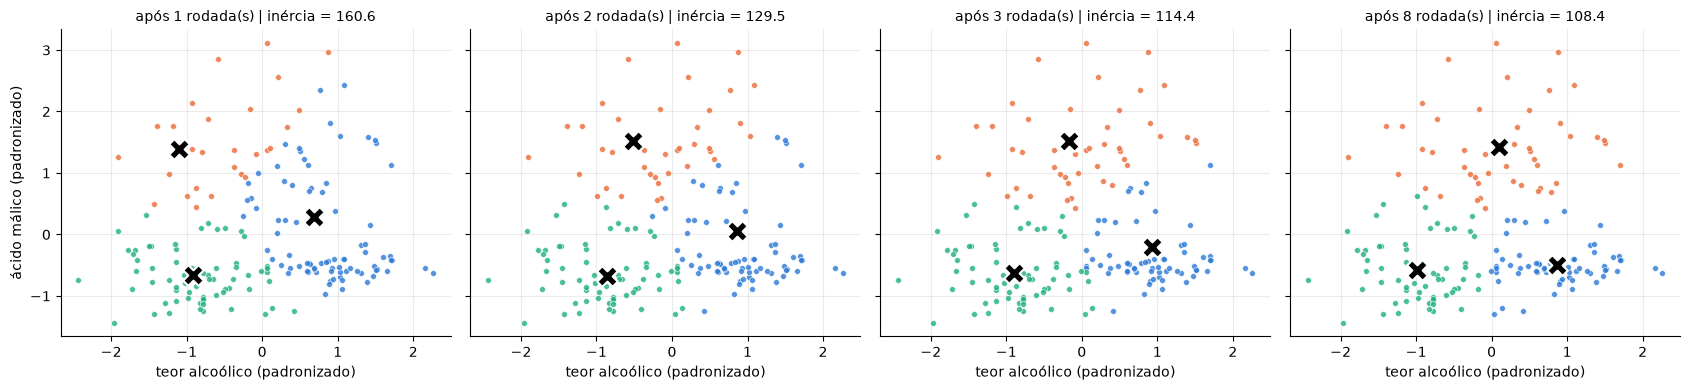

In [7]:
X2 = StandardScaler().fit_transform(vinhos[["Alcohol", "Malic_Acid"]])
inicio = X2[np.random.default_rng(7).choice(len(X2), size=3, replace=False)]   # 3 vinhos sorteados como início

fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, n_iter in zip(axes, [1, 2, 3, 8]):
    km2 = KMeans(n_clusters=3, init=inicio, n_init=1, max_iter=n_iter, random_state=SEED).fit(X2)
    for c in range(3):
        m = km2.labels_ == c
        ax.scatter(X2[m, 0], X2[m, 1], s=18, alpha=0.8, color=CORES_SLOTS[c], edgecolor="white", linewidth=0.5)
    ax.scatter(km2.cluster_centers_[:, 0], km2.cluster_centers_[:, 1], marker="X", s=220,
               c="black", edgecolor="white", lw=1.5)
    ax.set_title(f"após {n_iter} rodada(s) | inércia = {km2.inertia_:.1f}", fontsize=10)
    ax.set_xlabel("teor alcoólico (padronizado)")
axes[0].set_ylabel("ácido málico (padronizado)")
plt.tight_layout(); plt.show()

**Leitura:** a cada rodada os centróides (X) se movem e a inércia cai (de 160,6 para 108,4) até estabilizar. Como o
resultado depende dos pontos iniciais, usamos `n_init=10`: o K-Means roda 10 vezes e fica com o melhor resultado.

Só com álcool e acidez, os pontos formam uma nuvem sem grupos claros. Por isso o modelo usa as 13 variáveis.

### c.2 K-Means com as 13 variáveis

Começamos com **k = 3**, porque a base tem 3 tipos de uva. O item d) confirma se esse é o melhor valor.

In [8]:
km = KMeans(
    n_clusters=3,         # número de grupos (confirmado no item d)
    init="k-means++",     # escolhe centróides iniciais afastados entre si
    n_init=10,            # roda 10 vezes e fica com o melhor resultado
    random_state=SEED,
).fit(X)

rotulos_iniciais = km.labels_
print(f"inércia: {km.inertia_:,.2f} | rodadas até estabilizar: {km.n_iter_}")
print("vinhos por cluster:", dict(zip(*np.unique(rotulos_iniciais, return_counts=True))))

# Centro de cada grupo, de volta às unidades originais (%, g/L...)
centroides = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATURES)
centroides.rename_axis("cluster")

inércia: 1,277.93 | rodadas até estabilizar: 7
vinhos por cluster: {np.int32(0): np.int64(65), np.int32(1): np.int64(51), np.int32(2): np.int64(62)}


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
cluster,,,,,,,,,,,,,
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,"1,100.23"


**Leitura:** três grupos de tamanho parecido (51 a 65 vinhos), já com perfis diferentes: um com mais álcool e
prolina, um mais ácido e de cor intensa, e um com menos álcool. O item e) detalha cada um.

### c.3 Os outliers mudam os grupos?

Rodamos o K-Means de novo **sem** os 17 vinhos com outlier e comparamos com o modelo completo. A comparação usa o
**ARI**, visto na aula: 1 = grupos idênticos; 0 = nada em comum.

In [9]:
sem_outlier = ~eh_outlier.any(axis=1).to_numpy()
X_sem = StandardScaler().fit_transform(vinhos.loc[sem_outlier, FEATURES])
rotulos_sem = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_sem)

print(f"vinhos comparados: {sem_outlier.sum()}")
print(f"ARI com x sem outliers: {adjusted_rand_score(rotulos_iniciais[sem_outlier], rotulos_sem):.3f}")

vinhos comparados: 161
ARI com x sem outliers: 1.000


**Leitura:** ARI = 1,000. Os grupos são exatamente os mesmos, então manter os outliers foi seguro.

## d) Número de grupos: Cotovelo e Silhueta

- **Cotovelo:** a inércia sempre cai quando aumentamos o k. Procuramos o ponto em que ela para de cair rápido (a
  "dobra" da curva);
- **Silhueta:** mede se cada vinho está mais perto do seu grupo do que do grupo vizinho. Vai de −1 a 1, e
  **quanto maior, melhor**.

### d.1 Testando k de 2 a 10

,inércia,silhueta,queda da inércia (%)
k,,,
2,"1,658.759",0.259,NaN
3,"1,277.928",0.285,22.959
4,"1,175.428",0.260,8.021
5,"1,109.513",0.202,5.608
6,"1,046.002",0.237,5.724
7,981.595,0.204,6.157
8,935.201,0.157,4.726
9,889.893,0.150,4.845
10,845.895,0.144,4.944


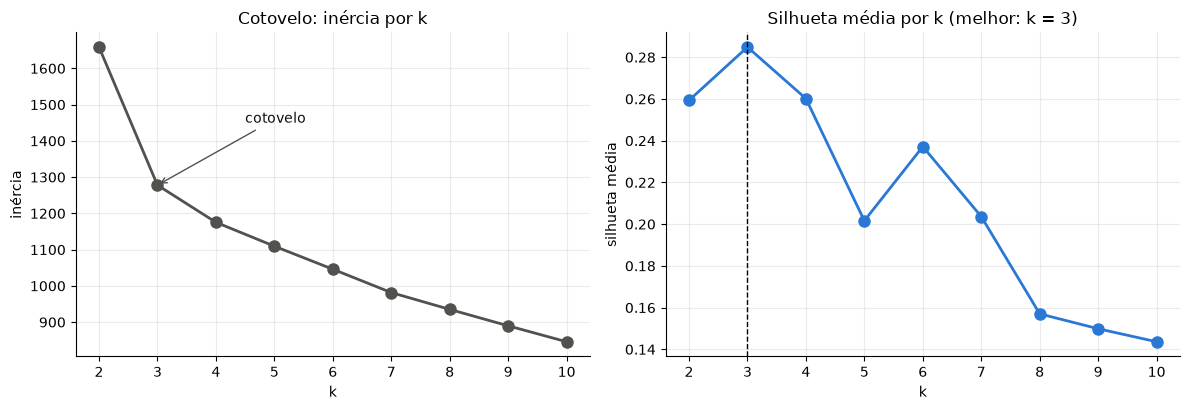

In [10]:
resultados = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    resultados.append({"k": k, "inércia": km_k.inertia_, "silhueta": silhouette_score(X, km_k.labels_)})
resultados = pd.DataFrame(resultados).set_index("k")
resultados["queda da inércia (%)"] = -resultados["inércia"].pct_change() * 100   # em relação ao k anterior
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(resultados)

k_melhor = resultados["silhueta"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(resultados.index, resultados["inércia"], "o-", color="#52514e", lw=2, ms=8)
axes[0].annotate("cotovelo", xy=(3, resultados.loc[3, "inércia"]), xytext=(4.5, 1450),
                 arrowprops=dict(arrowstyle="->", color="#52514e"), color="#0b0b0b")
axes[0].set(title="Cotovelo: inércia por k", xlabel="k", ylabel="inércia")
axes[1].plot(resultados.index, resultados["silhueta"], "o-", color=CORES_SLOTS[0], lw=2, ms=8)
axes[1].axvline(k_melhor, ls="--", color="black", lw=1)
axes[1].set(title=f"Silhueta média por k (melhor: k = {k_melhor})", xlabel="k", ylabel="silhueta média")
plt.tight_layout(); plt.show()

**Leitura:**

- **Cotovelo:** até k = 3 a inércia cai 23%; depois, no máximo 8%. A dobra está em **k = 3**;
- **Silhueta:** o maior valor é **0,285, em k = 3**.

Os dois métodos concordam: **k = 3**. A silhueta de 0,285 é moderada: os grupos existem, mas alguns vinhos ficam na
fronteira entre dois grupos.

### d.2 Silhueta de cada grupo

O gráfico mostra a silhueta de cada vinho, separada por grupo. Barras largas e positivas indicam um grupo bem
formado. Barras negativas são vinhos que parecem estar no grupo errado.

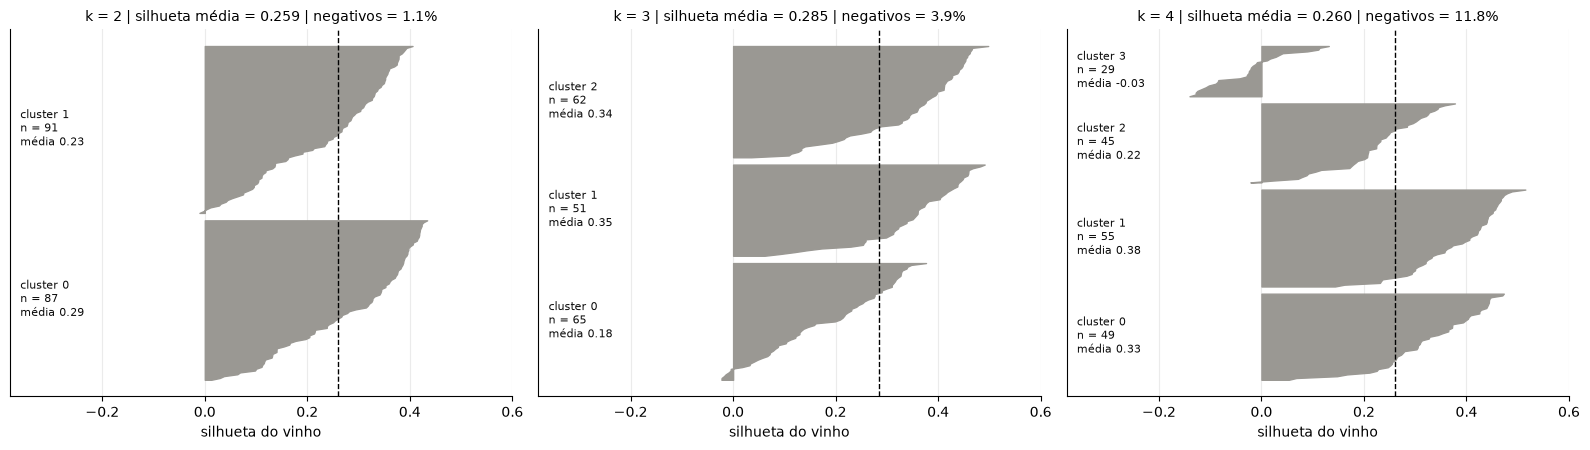

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    rotulos_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    sil = silhouette_samples(X, rotulos_k)        # silhueta de cada vinho
    y0 = 3
    for c in range(k):
        valores = np.sort(sil[rotulos_k == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(valores)), 0, valores, color="#9a9893")
        ax.text(-0.36, y0 + len(valores) / 2, f"cluster {c}\nn = {len(valores)}\nmédia {valores.mean():.2f}",
                fontsize=8, va="center", color="#0b0b0b")
        y0 += len(valores) + 3
    ax.axvline(sil.mean(), ls="--", color="black", lw=1)
    ax.set_title(f"k = {k} | silhueta média = {sil.mean():.3f} | negativos = {(sil < 0).mean():.1%}", fontsize=10)
    ax.set_yticks([]); ax.set_xlabel("silhueta do vinho"); ax.set_xlim(-0.38, 0.6)
plt.tight_layout(); plt.show()

**Leitura:**

- **k = 2:** dois grupos grandes e fracos (0,23 e 0,29), misturando perfis diferentes;
- **k = 3:** três grupos equilibrados e só 3,9% de vinhos negativos. Um deles é mais fraco (0,18), com vinhos na
  fronteira;
- **k = 4:** um grupo fica com silhueta negativa e os negativos sobem para 11,8%. O algoritmo dividiu um grupo que
  não devia ser dividido.

**Decisão: k = 3.**

### d.3 Modelo final

Juntamos as etapas num `Pipeline`, como na aula: preencher nulos → padronizar → K-Means. Assim, um vinho novo
passa exatamente pelos mesmos passos.

In [12]:
K_FINAL = 3

modelo = Pipeline([
    ("imputa", SimpleImputer(strategy="median")),   # preenche medidas faltantes (hoje não há nenhuma)
    ("padroniza", StandardScaler()),                 # todas as variáveis com o mesmo peso
    ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED)),
])
vinhos["cluster"] = modelo.fit_predict(vinhos[FEATURES])

print(f"silhueta do modelo final: {silhouette_score(X, vinhos['cluster']):.3f}")
vinhos["cluster"].value_counts().sort_index().rename("vinhos por cluster")

silhueta do modelo final: 0.285


cluster
0    65
1    51
2    62
Name: vinhos por cluster, dtype: int64

## e) Análise dos grupos

### e.1 Perfil de cada grupo

O K-Means devolve só números (0, 1, 2). Para dar nome aos grupos, comparamos a média de cada um com a média geral.

In [13]:
perfil = vinhos.groupby("cluster")[FEATURES].mean()
perfil.insert(0, "vinhos", vinhos["cluster"].value_counts().sort_index())
perfil.insert(1, "% dos vinhos", perfil["vinhos"] / len(vinhos) * 100)

# Os números dos clusters podem mudar de um computador para outro, então o nome vem de regras:
#   1) maior teor alcoólico       -> "Encorpados"
#   2) dos restantes, mais ácido  -> "Ácidos"
#   3) o que sobrar               -> "Leves"
restantes, nomes = list(perfil.index), {}
for nome, coluna in [("Encorpados", "Alcohol"), ("Ácidos", "Malic_Acid")]:
    escolhido = perfil.loc[restantes, coluna].idxmax()
    nomes[escolhido] = nome
    restantes.remove(escolhido)
nomes[restantes[0]] = "Leves"

ORDEM = ["Encorpados", "Ácidos", "Leves"]
CORES = dict(zip(ORDEM, CORES_SLOTS))         # cada grupo tem sempre a mesma cor
vinhos["grupo"] = vinhos["cluster"].map(nomes)

perfil_nomeado = perfil.rename(index=nomes).loc[ORDEM]
perfil_nomeado.loc["MÉDIA GERAL"] = [len(vinhos), 100.0] + vinhos[FEATURES].mean().tolist()
perfil_nomeado.T

cluster,Encorpados,Ácidos,Leves,MÉDIA GERAL
vinhos,62.00,51.00,65.00,178.00
% dos vinhos,34.83,28.65,36.52,100.00
Alcohol,13.68,13.13,12.25,13.00
Malic_Acid,2.00,3.31,1.90,2.34
Ash,2.47,2.42,2.23,2.37
Ash_Alcanity,17.46,21.24,20.06,19.49
Magnesium,107.97,98.67,92.74,99.74
Total_Phenols,2.85,1.68,2.25,2.30
Flavanoids,3.00,0.82,2.05,2.03
Nonflavanoid_Phenols,0.29,0.45,0.36,0.36


**Leitura:** cada grupo tem um perfil químico próprio. Os nomes vêm das perguntas do enunciado: o grupo com mais
álcool é o **Encorpados**, o mais ácido é o **Ácidos** e o restante é o **Leves**.

### e.2 Qual o teor alcoólico de cada grupo?

,média,mediana,mínimo,máximo,CV (%),vinhos com ≥ 14%
grupo,,,,,,
Encorpados,13.68,13.73,11.56,14.83,4.09,19
Ácidos,13.13,13.11,12.20,14.34,3.97,3
Leves,12.25,12.25,11.03,13.86,4.35,0


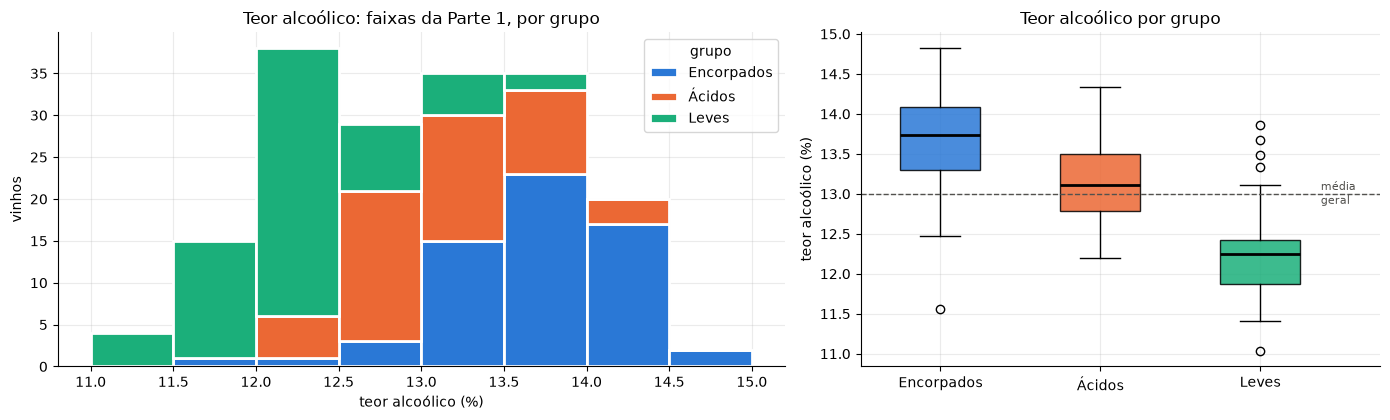

In [14]:
def resumo(coluna):
    # Média, mediana, mínimo, máximo e CV de cada grupo (as mesmas medidas da Parte 1)
    g = vinhos.groupby("grupo")[coluna]
    return pd.DataFrame({"média": g.mean(), "mediana": g.median(), "mínimo": g.min(),
                         "máximo": g.max(), "CV (%)": g.std() / g.mean() * 100}).loc[ORDEM]

def grafico_por_grupo(coluna, limites, rotulo, titulo):
    # Esquerda: histograma com as mesmas faixas da Parte 1, colorido por grupo
    # Direita: boxplot de cada grupo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
    ax1.hist([vinhos.loc[vinhos["grupo"] == g, coluna] for g in ORDEM], bins=limites, stacked=True,
             color=[CORES[g] for g in ORDEM], label=ORDEM, edgecolor="white", linewidth=2)
    ax1.set(xticks=limites, xlabel=rotulo, ylabel="vinhos", title=f"{titulo}: faixas da Parte 1, por grupo")
    ax1.legend(title="grupo")
    caixas = ax2.boxplot([vinhos.loc[vinhos["grupo"] == g, coluna] for g in ORDEM], tick_labels=ORDEM,
                         patch_artist=True, widths=0.5, medianprops=dict(color="black", lw=2))
    for caixa, g in zip(caixas["boxes"], ORDEM):
        caixa.set(facecolor=CORES[g], alpha=0.85)
    ax2.axhline(vinhos[coluna].mean(), ls="--", color="#52514e", lw=1)
    ax2.text(3.38, vinhos[coluna].mean(), "média\ngeral", va="center", fontsize=8, color="#52514e")
    ax2.set(xlim=(0.5, 3.75), ylabel=rotulo, title=f"{titulo} por grupo")
    plt.tight_layout(); plt.show()

alcool = resumo("Alcohol")
alcool["vinhos com ≥ 14%"] = vinhos[vinhos["Alcohol"] >= 14].groupby("grupo").size().reindex(ORDEM, fill_value=0)
display(alcool)
grafico_por_grupo("Alcohol", np.arange(11, 15.01, 0.5), "teor alcoólico (%)", "Teor alcoólico")

**Leitura:**

- **Encorpados:** o maior teor alcoólico (média de **13,68%**). Tem 19 dos 22 vinhos com 14% ou mais;
- **Ácidos:** teor médio (**13,13%**), perto da média geral (13,00%);
- **Leves:** o menor teor (**12,25%**). Nenhum vinho deste grupo chega a 14%.

**H1 confirmada:** no histograma da Parte 1, agora colorido por grupo, o pico de 12–12,5% é quase todo dos Leves, e
o pico de 13–14% é dos Encorpados e Ácidos. Os dois picos eram grupos diferentes misturados.

### e.3 Qual o grupo mais ácido?

,média,mediana,mínimo,máximo,CV (%),vinhos com > 3 g/L
grupo,,,,,,
Encorpados,2.00,1.77,1.35,4.04,33.82,7
Ácidos,3.31,3.27,1.24,5.65,33.06,32
Leves,1.90,1.61,0.74,5.80,53.35,8


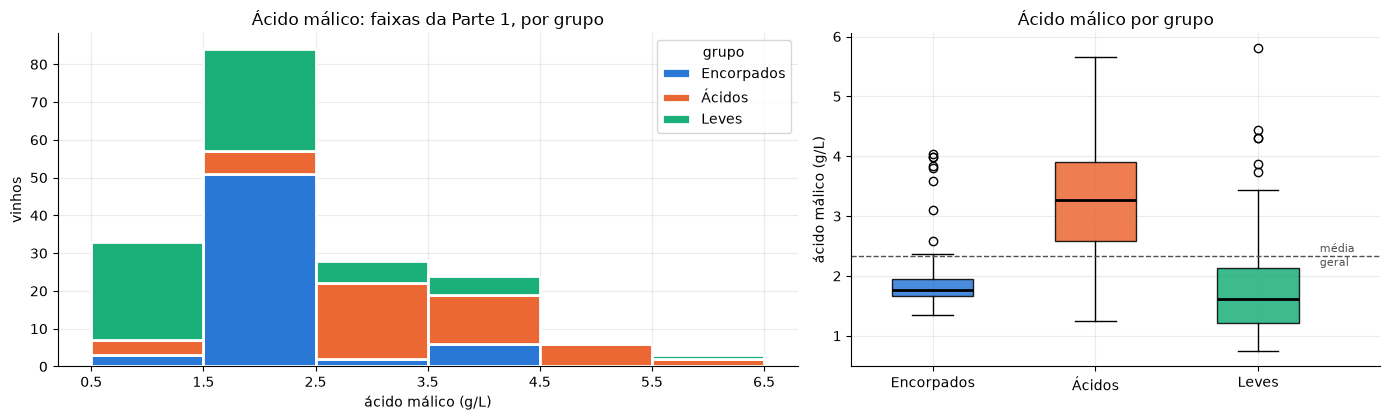

,Malic_Acid,Alcohol,Color_Intensity,Proline,grupo
123,5.80,13.05,2.60,380,Leves
137,5.51,12.53,5.00,515,Ácidos
173,5.65,13.71,7.70,740,Ácidos


In [15]:
acido = resumo("Malic_Acid")
acido["vinhos com > 3 g/L"] = vinhos[vinhos["Malic_Acid"] > 3].groupby("grupo").size().reindex(ORDEM, fill_value=0)
display(acido)
grafico_por_grupo("Malic_Acid", np.arange(0.5, 6.51, 1), "ácido málico (g/L)", "Ácido málico")

# Em que grupo ficaram os 3 vinhos mais ácidos (os outliers da Parte 1)?
vinhos.loc[eh_outlier["Malic_Acid"], ["Malic_Acid", "Alcohol", "Color_Intensity", "Proline", "grupo"]]

**Leitura:**

- O grupo **Ácidos** é o mais ácido: média de **3,31 g/L**, contra 2,00 nos Encorpados e 1,90 nos Leves;
- Ele reúne 32 dos 47 vinhos com mais de 3 g/L (68%);
- O vinho mais ácido de todos (5,80 g/L) ficou nos Leves, porque no resto das medidas (cor clara, pouca prolina)
  ele se parece com esse grupo. O K-Means olha as 13 variáveis juntas.

**H2 confirmada em parte:** existe um grupo mais ácido, mas ele não é formado só pela acidez.

### e.4 Cinzas e o que mais diferencia os grupos

,média,mediana,mínimo,máximo,CV (%)
grupo,,,,,
Encorpados,2.47,2.45,2.04,3.23,9.95
Ácidos,2.42,2.38,1.98,2.86,8.23
Leves,2.23,2.24,1.36,2.92,13.41


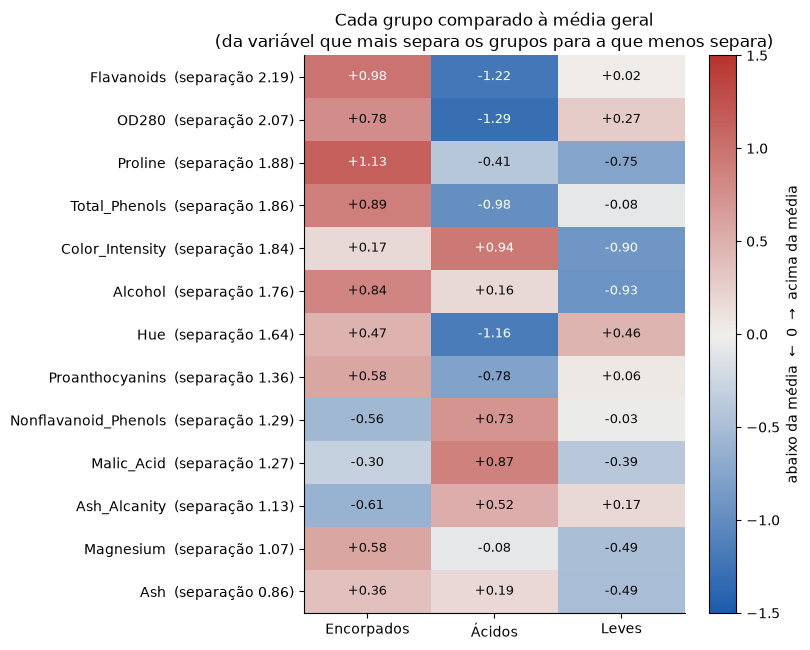

In [16]:
display(resumo("Ash"))

# Mapa de calor: média de cada grupo comparada à média geral, em desvios padrão
# (0 = igual à média; +1 = bem acima; -1 = bem abaixo).
# "separação" = maior valor - menor valor: quanto maior, mais a variável diferencia os grupos.
z = pd.DataFrame(X, columns=FEATURES).groupby(vinhos["grupo"].to_numpy()).mean().loc[ORDEM].T
z["separação"] = z.max(axis=1) - z.min(axis=1)
z = z.sort_values("separação", ascending=False)

DIVERGENTE = LinearSegmentedColormap.from_list("azul_cinza_vermelho", ["#1c5cab", "#f0efec", "#b8332f"])
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(z[ORDEM], cmap=DIVERGENTE, vmin=-1.5, vmax=1.5, aspect="auto")
for i, variavel in enumerate(z.index):
    for j, g in enumerate(ORDEM):
        valor = z.loc[variavel, g]
        ax.text(j, i, f"{valor:+.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(valor) > 0.9 else "#0b0b0b")
ax.set_xticks(range(len(ORDEM)), ORDEM)
ax.set_yticks(range(len(z)), [f"{v}  (separação {s:.2f})" for v, s in zip(z.index, z["separação"])])
ax.grid(False)
fig.colorbar(im, ax=ax, label="abaixo da média  ←  0  →  acima da média")
ax.set_title("Cada grupo comparado à média geral\n(da variável que mais separa os grupos para a que menos separa)")
plt.tight_layout(); plt.show()

**Leitura:**

- **Cinzas:** os Leves têm menos cinzas (2,23) e os Encorpados mais (2,47). Mas é a variável que **menos** separa os
  grupos (a última do mapa);
- **O que mais separa os grupos:** flavonoides, OD280, prolina, fenóis e cor. O ácido málico fica só em
  **10º lugar**.

**H3 não confirmada.** A tabela abaixo mostra por quê.

In [17]:
# CV no conjunto todo (Parte 1) x CV dentro de cada grupo
cv_geral = vinhos[["Alcohol", "Malic_Acid"]].std() / vinhos[["Alcohol", "Malic_Acid"]].mean() * 100
cv_grupos = vinhos.groupby("grupo")[["Alcohol", "Malic_Acid"]].agg(lambda s: s.std() / s.mean() * 100).T[ORDEM]
cv_grupos.insert(0, "CV geral (Parte 1)", cv_geral)
cv_grupos.rename_axis("CV (%)")

grupo,CV geral (Parte 1),Encorpados,Ácidos,Leves
CV (%),,,,
Alcohol,6.24,4.09,3.97,4.35
Malic_Acid,47.82,33.82,33.06,53.35


**Leitura:** a acidez varia muito **dentro** de cada grupo (CV de 33% a 53%), então ajuda pouco a separá-los. O
álcool varia pouco dentro dos grupos (CV de cerca de 4%) e muito **entre** eles. Ou seja: variar muito não significa
separar bem.

### e.5 Os grupos em 2D

O K-Means usou 13 variáveis. Para visualizar, o `PCA` resume tudo em 2 eixos (como na aula).

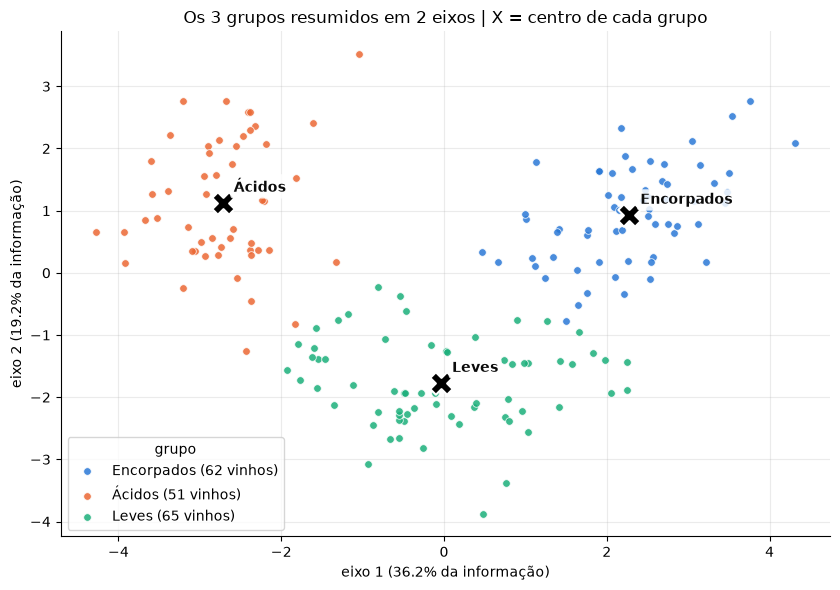

In [18]:
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X)
centroides_2d = pca.transform(modelo.named_steps["kmeans"].cluster_centers_)
var = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8.5, 6))
for g in ORDEM:
    m = (vinhos["grupo"] == g).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=30, alpha=0.85, color=CORES[g], edgecolor="white", linewidth=0.6,
               label=f"{g} ({m.sum()} vinhos)")
for c, (x, y) in enumerate(centroides_2d):
    ax.scatter(x, y, marker="X", s=260, c="black", edgecolor="white", lw=1.5)
    ax.annotate(nomes[c], (x, y), xytext=(8, 8), textcoords="offset points", fontsize=10,
                fontweight="bold", color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
ax.set(xlabel=f"eixo 1 ({var[0]:.1%} da informação)", ylabel=f"eixo 2 ({var[1]:.1%} da informação)",
       title="Os 3 grupos resumidos em 2 eixos | X = centro de cada grupo")
ax.legend(title="grupo")
plt.tight_layout(); plt.show()

**Leitura:** os três grupos aparecem bem separados. A pouca mistura que existe fica na borda dos Leves, o grupo com a
silhueta mais baixa.

### e.6 Resumo de cada grupo

| Grupo | Vinhos | Álcool | Acidez | Cinzas | Destaques |
|---|---|---|---|---|---|
| **1 · Encorpados** | 62 | **o maior** (13,68%) | baixa (2,00 g/L) | **mais** (2,47) | muita prolina e flavonoides |
| **2 · Ácidos** | 51 | médio (13,13%) | **a maior** (3,31 g/L) | médias (2,42) | cor intensa, poucos flavonoides |
| **3 · Leves** | 65 | **o menor** (12,25%) | a menor (1,90 g/L) | **menos** (2,23) | cor clara, pouca prolina |

No formato do exemplo do enunciado:

- **Grupo 1 · Encorpados:** maior teor alcoólico, pouco ácidos, mais cinzas, muita prolina e flavonoides;
- **Grupo 2 · Ácidos:** mais ácidos, teor alcoólico médio, cor intensa e poucos flavonoides;
- **Grupo 3 · Leves:** menor teor alcoólico, menos ácidos, pouca cinza, cor clara e pouca prolina.

## Validação: abrindo o cofre

A versão original da base tem o tipo de uva (cultivar) de cada vinho, e ela vem pronta no scikit-learn
(`load_wine`). Como na aula, usamos essa resposta **só no final**, para conferir o resultado. Ela não entrou no
modelo.

In [19]:
from sklearn.datasets import load_wine     # importado só aqui: a resposta não participa do modelo

original = load_wine(as_frame=True)
print("mesmos 178 vinhos, na mesma ordem:", np.allclose(original.data.to_numpy(), vinhos[FEATURES].to_numpy()))

cultivar = original.target.map({0: "cultivar 1", 1: "cultivar 2", 2: "cultivar 3"}).rename("tipo de uva")
display(pd.crosstab(cultivar, vinhos["grupo"])[ORDEM])
print(f"ARI contra o tipo de uva: {adjusted_rand_score(cultivar, vinhos['grupo']):.3f}")

mesmos 178 vinhos, na mesma ordem: True


grupo,Encorpados,Ácidos,Leves
tipo de uva,,,
cultivar 1,59,0,0
cultivar 2,3,3,65
cultivar 3,0,48,0


ARI contra o tipo de uva: 0.897


**Leitura:** cada grupo é praticamente um tipo de uva: Encorpados = cultivar 1, Ácidos = cultivar 3 e Leves =
cultivar 2. Só 6 dos 178 vinhos ficaram em outro grupo (ARI = 0,897). Sem ver a resposta, o K-Means reencontrou os
3 tipos de uva.

### A armadilha da aula: silhueta alta não garante bons grupos

Comparamos o modelo escolhido com outras opções de preparação dos dados.

In [20]:
cenarios = {
    "13 variáveis + StandardScaler (escolhido)": StandardScaler().fit_transform(vinhos[FEATURES]),
    "13 variáveis + MinMaxScaler": MinMaxScaler().fit_transform(vinhos[FEATURES]),
    "13 variáveis sem padronizar": vinhos[FEATURES].to_numpy(),
    "só álcool e acidez (Parte 1)": StandardScaler().fit_transform(vinhos[["Alcohol", "Malic_Acid"]]),
}
linhas = []
for nome, Xc in cenarios.items():
    rotulos_c = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(Xc)
    linhas.append({"cenário": nome, "silhueta": silhouette_score(Xc, rotulos_c),
                   "ARI contra o tipo de uva": adjusted_rand_score(cultivar, rotulos_c)})
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.DataFrame(linhas).set_index("cenário"))

,silhueta,ARI contra o tipo de uva
cenário,,
13 variáveis + StandardScaler (escolhido),0.285,0.897
13 variáveis + MinMaxScaler,0.301,0.854
13 variáveis sem padronizar,0.571,0.371
só álcool e acidez (Parte 1),0.484,0.444


**Leitura:**

- **Sem padronizar:** a silhueta sobe (0,571), mas os grupos ficam muito piores (ARI de 0,371), porque o modelo só
  olha a prolina;
- **Só álcool e acidez:** grupos ruins (ARI de 0,444). As duas variáveis da Parte 1 sozinhas não bastam;
- **MinMaxScaler:** bom (ARI de 0,854), mas abaixo do StandardScaler (0,897).

Como visto na aula: a silhueta serve para escolher o k, mas não para comparar formas diferentes de preparar os dados.

## Conclusão

Com a base da Parte 1 padronizada, o K-Means encontrou **3 grupos** de vinhos. O cotovelo e a silhueta concordaram
nesse número.

| Grupo | Teor alcoólico | Acidez | Cinzas | Destaques |
|---|---|---|---|---|
| **Encorpados** | o maior (13,68%) | baixa (2,00 g/L) | mais (2,47) | muita prolina e flavonoides |
| **Ácidos** | médio (13,13%) | **a maior** (3,31 g/L) | médias (2,42) | cor intensa, poucos flavonoides |
| **Leves** | o menor (12,25%) | a menor (1,90 g/L) | menos (2,23) | cor clara, pouca prolina |

**Hipóteses da Parte 1:**

- **H1 confirmada:** os dois picos do teor alcoólico eram grupos diferentes;
- **H2 confirmada em parte:** existe um grupo mais ácido, mas ele é definido por várias variáveis, não só pela
  acidez;
- **H3 não confirmada:** quem mais separa os grupos são flavonoides, prolina, fenóis, cor e álcool, e não a acidez.

**Validação:** os grupos correspondem aos 3 tipos de uva. Só 6 dos 178 vinhos ficaram fora do lugar.

**Limites:** o K-Means sempre devolve k grupos, depende da escala dos dados e funciona melhor com grupos bem
separados. Aqui, alguns vinhos ficam na fronteira entre dois grupos (silhueta de 0,285).